# Historical baselines and candidate (2026-11-16)

This notebook reproduces the historical 100-tree/depth-3 candidate. The latest
nested-CV selection uses 300 trees, learning rate 0.2, and depth 2; its 2024 AP
is 0.590379. The final-evaluation CLI separately freezes calibration and scores
2025; see the [evaluation protocol](../docs/evaluation.md#frozen-2025-evaluation-protocol).
This notebook never reads final test outcomes. The historical experiment fits
on 2017–2023 and compares on 2024. The reference
is the training-derived storm-family rate times county history. Model selection
uses average precision, Brier score and recall at the top 10% of rows.

The chosen candidate uses nineteen inputs: four time/pre-storm inputs, twelve
storm-family counts, and three county-history inputs. See
[evaluation policy](../docs/evaluation.md) for exact criteria and diagnostics.


In [1]:
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
from outage_prediction.config import ProjectPaths
from outage_prediction.train import load_model_data, fit_model, save_run
from outage_prediction.plots import calibration_plot, pr_curve_plot
from outage_prediction.evaluation import naive_rules

train, validation, sources = load_model_data(ProjectPaths(offline=True))


## Establish the no-ML and logistic baselines

Median imputation, missing indicators and logistic scaling are fitted on training
rows only. The threshold table is exploratory; it does not choose an operational
alert threshold. The initial logistic model does not beat the reference.


In [2]:
baseline = fit_model(train, validation, kind="baseline", sources=sources)
display(baseline.tables["baseline_comparison"][["rule", "pr_auc", "brier", "recall_top10"]])
display(baseline.tables["threshold_comparison"])


,rule,pr_auc,brier,recall_top10
0,always_train_rate,0.164821,0.138209,0.092773
1,family_rate,0.311540,0.124579,0.231641
2,county_history,0.367712,0.123843,0.269336
3,family_x_history,0.469056,0.111560,0.325781
4,logistic_regression,0.363576,0.125422,0.242383


,threshold,recall,precision,missed_outages,false_alarms,false_alarms_per_1000
0,0.05,1.000000,0.164821,0,25944,835.178985
1,0.10,0.930469,0.180468,356,21634,696.433170
2,0.15,0.338281,0.322773,3388,3634,116.984290
3,0.20,0.183008,0.562763,4183,728,23.435488
4,0.30,0.134180,0.682224,4433,320,10.301313
5,0.50,0.102539,0.833333,4595,105,3.380118


## Fit the selected nineteen-input candidate

Use the existing 100 trees, learning rate 0.1, depth 3, and seed 42. There is no
hyperparameter search, early stopping, fitted calibration, or random validation
split. Bootstrap is explicitly opt-in; the historical comparison below records
the completed uncertainty analysis.


,pr_auc,roc_auc,brier,recall_top10,passes_all_validation
logistic,0.363576,0.659956,0.125422,0.242383,False
boosting,0.588047,0.843836,0.098849,0.400977,True


,group,rows,pos_rate,pr_auc,reference_pr_auc,beats_reference
0,tstm_wind,9206,0.289920,0.623276,0.512251,True
1,winter,7924,0.077486,0.292043,0.205003,True
2,high_wind,4676,0.176433,0.579183,0.455169,True
3,hail,4012,0.154786,0.493509,0.384118,True
4,flood,3977,0.184058,0.675334,0.494854,True
5,tornado,1482,0.373819,0.755197,0.617259,True


,group,rows,pos_rate,pr_auc,reference_pr_auc,beats_reference
0,FEMA 1,799,0.232791,0.523451,0.389178,True
1,FEMA 2,1181,0.184589,0.561747,0.412505,True
2,FEMA 3,3031,0.204223,0.581043,0.422893,True
3,FEMA 4,5115,0.269795,0.729328,0.601672,True
4,FEMA 5,4386,0.145235,0.491741,0.317721,True
5,FEMA 6,4105,0.229233,0.658820,0.575370,True
6,FEMA 7,3710,0.136388,0.461079,0.340554,True
7,FEMA 8,5134,0.061356,0.278556,0.179156,True
8,FEMA 9,2185,0.073227,0.340990,0.218738,True
9,FEMA 10,1418,0.111425,0.419587,0.300974,True


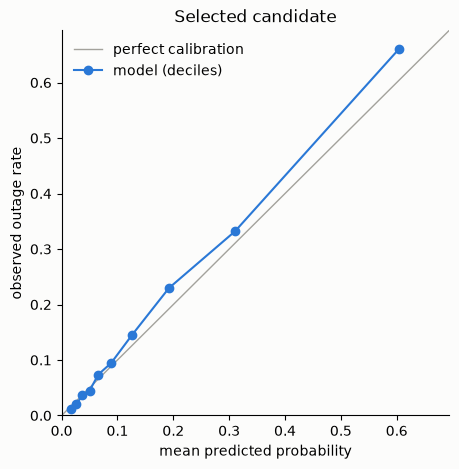

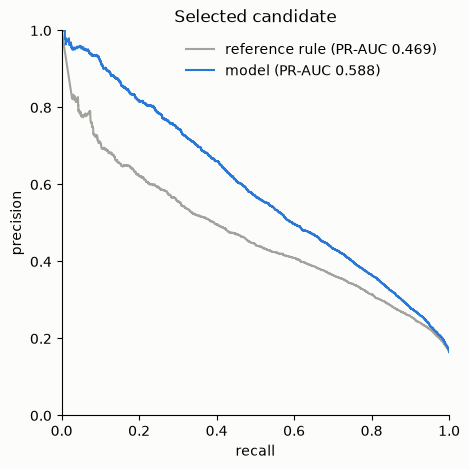

In [3]:
candidate = fit_model(train, validation, sources=sources)
display(pd.DataFrame([baseline.metrics, candidate.metrics], index=["logistic", "boosting"])[
    ["pr_auc", "roc_auc", "brier", "recall_top10", "passes_all_validation"]])
display(candidate.tables["by_family"])
display(candidate.tables["by_fema_region"])
figure = calibration_plot(candidate.tables["calibration_deciles"], "Selected candidate")
display(figure)
plt.close(figure)
figure = pr_curve_plot(validation.target.to_numpy(), candidate.predictions.probability.to_numpy(),
                       naive_rules(train, validation)["family_x_history"], "Selected candidate")
display(figure)
plt.close(figure)


## Historical feature-selection evidence — 2026-11-16

The comparison below is a preserved historical result, not a fresh four-model
experiment executed by this notebook. All settings were fixed; intervals are
exploratory and unadjusted for multiple comparisons.

### Validation results

| Inputs | Features | Average precision (PR-AUC), higher better | Brier, lower better | Recall at top 10% | Positives caught | Pass all reference checks |
|---|---:|---:|---:|---:|---:|---|
| Base | 4 | 0.399415 | 0.121035 | 26.58% | 1,361 | No |
| Base + storm | 16 | 0.514131 | 0.108638 | 34.73% | 1,778 | Yes |
| Base + history | 7 | 0.494883 | 0.110950 | 33.46% | 1,713 | Yes |
| Base + storm + history | 19 | **0.588047** | **0.098849** | **40.10%** | **2,053** | **Yes** |
| Reference family-times-history rule | Not fitted | 0.469056 | 0.111560 | 32.58% | 1,668 | Comparator |

Every top-10% selection flags 3,107 validation rows. Combined features catch 692
more positives than base and 385 more than the reference at that same budget.
Combined precision at top 10% is 66.08%. The selection budget is illustrative,
not a measured utility staffing capacity. Pass/fail uses full precision and
the three checks in [evaluation criteria](../docs/evaluation.md).

### Uncertainty

Paired percentile 95% intervals for average-precision gains, using 1,000 identical
episode-level bootstrap draws across models (seed 42):

| Comparison | AP gain | 95% interval |
|---|---:|---|
| Add storm to base | 0.114716 | [0.100292, 0.130010] |
| Add history to base | 0.095467 | [0.084508, 0.106987] |
| Add both to base | 0.188631 | [0.173392, 0.205037] |
| Add history to base + storm | 0.073915 | [0.063954, 0.083828] |
| Add storm to base + history | 0.093164 | [0.081020, 0.105532] |
| Combined versus reference | 0.118991 | [0.103937, 0.135048] |

All intervals are above zero. These are exploratory comparisons, unadjusted for
multiple comparisons, conditional on the fitted models and this validation year.
They do not include uncertainty from retraining or establish performance in 2025.



## Interpretation, provenance, and persistence

Both storm and history groups improved validation in the historical comparison.
This does not establish that every feature is needed or validate live forecasting.
Training histories exclude county sums for the row's year, but their smoothing
priors use all training labels. Whole-episode reports may occur after prediction
time. A chronological redesign requires a separate dataset experiment.

Notebook execution creates no model run or report files. To retain this fit,
call `save_run(candidate, new_run_directory, validation, train)` explicitly.
That saves the pipeline, keyed predictions, metrics, diagnostic tables, charts,
and provenance. Upload is a separate explicit command documented in the README.

Historical run directories now live in `models/gradient_boosting/`. Their
original manifests remain unchanged. Recorded W&B links were preserved without
contacting the service during this refactor. Comparison model artifacts uploaded
before the metrics-attachment fix may contain the last model's metrics file;
remote artifact repair has not been performed.

- feature-comparison-2026-11-16 / base: [recorded run](https://forge.coreweave.com/wandb/leslie-ortega-us-georgia-state-university/CAPSTONE%20MODEL/runs/7b02b3f4ef85f21d)
- feature-comparison-2026-11-16 / base_storm: [recorded run](https://forge.coreweave.com/wandb/leslie-ortega-us-georgia-state-university/CAPSTONE%20MODEL/runs/9cdd23b0561d7d59)
- feature-comparison-2026-11-16 / base_history: [recorded run](https://forge.coreweave.com/wandb/leslie-ortega-us-georgia-state-university/CAPSTONE%20MODEL/runs/5490258b2cc8084b)
- feature-comparison-2026-11-16 / base_storm_history: [recorded run](https://forge.coreweave.com/wandb/leslie-ortega-us-georgia-state-university/CAPSTONE%20MODEL/runs/fa30cc5ca3bd9d1a)
- expanded-candidate-2026-11-16 / base_storm_history: [recorded run](https://forge.coreweave.com/wandb/leslie-ortega-us-georgia-state-university/CAPSTONE%20MODEL/runs/10965cbc72446825)